# Gurgaon Real Estate Price Prediction — Backend Pipeline

One consolidated notebook covering every main step of the original multi-notebook project: raw data cleaning, merging, feature engineering, outlier treatment, missing-value imputation, feature selection, model comparison, and exporting the final model for the Streamlit frontend (`app.py`, in this same folder).

Run all cells top to bottom. It reads `flats.csv`, `houses.csv`, and `appartments.csv` (already copied into this folder) and ends by writing `pipeline.pkl` and `df.pkl`, which `app.py` loads.

**Notes on deviations from the original notebooks** (documented inline where they occur):
- The original project shuffled the merged dataset with `df.sample(...)` without a fixed seed, then used **hardcoded row indices** (e.g. `df.drop(index=[818, 1796, ...])`, `df.loc[955,'sector']=...`) to hand-fix specific rows found by manually inspecting outputs. Since the shuffle was never seeded, those indices aren't tied to any reproducible row and can't be safely replayed here. This notebook seeds the shuffle (`random_state=42`) for full reproducibility and replaces every hardcoded-index fix with an equivalent **condition-based** rule, so re-running this notebook always gives the same result.
- `outlier-treatment.ipynb` and `feature-selection.ipynb` in the original project produce `gurgaon_properties_outlier_treated.csv` and `gurgaon_properties_post_feature_selection_v2.csv` respectively, but neither notebook actually contains the code that writes those files (confirmed by inspecting the saved `.ipynb` — there's no matching `to_csv` call, yet `missing-value-imputation.ipynb` and `model-selection.ipynb` both read them). This notebook reconstructs both steps from the transformation logic that *is* present, verified against the actual CSVs shipped in the project.

## 0. Setup

In [1]:
import re
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MultiLabelBinarizer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

## 1. Clean raw flats listings
Parses the scraped `flats.csv` text fields (price, area, bedrooms, etc.) into numeric/clean columns. Mirrors `data-preprocessing-flats.ipynb`.

In [2]:
flats = pd.read_csv('flats.csv')
flats = flats.drop(columns=['link', 'property_id'])
flats = flats.rename(columns={'area': 'price_per_sqft'})

flats['society'] = (
    flats['society']
    .apply(lambda name: re.sub(r'\d+(\.\d+)?\s?★', '', str(name)).strip())
    .str.lower()
)

flats = flats[flats['price'] != 'Price on Request']


def treat_price(x):
    if isinstance(x, float):
        return x
    if x[1] == 'Lac':
        return round(float(x[0]) / 100, 2)
    return round(float(x[0]), 2)


flats['price'] = flats['price'].str.split(' ').apply(treat_price)
flats['price_per_sqft'] = (
    flats['price_per_sqft']
    .str.split('/').str.get(0)
    .str.replace('₹', '').str.replace(',', '').str.strip()
    .astype(float)
)

flats = flats[~flats['bedRoom'].isnull()]
flats['bedRoom'] = flats['bedRoom'].str.split(' ').str.get(0).astype(int)
flats['bathroom'] = flats['bathroom'].str.split(' ').str.get(0).astype(int)
flats['balcony'] = flats['balcony'].str.split(' ').str.get(0).str.replace('No', '0')

flats['additionalRoom'] = flats['additionalRoom'].fillna('not available').str.lower()

flats['floorNum'] = (
    flats['floorNum']
    .str.split(' ').str.get(0)
    .replace('Ground', '0')
    .str.replace('Basement', '-1')
    .str.replace('Lower', '0')
    .str.extract(r'(\d+)')
)

flats['facing'] = flats['facing'].fillna('NA')
flats.insert(loc=4, column='area', value=round((flats['price'] * 10000000) / flats['price_per_sqft']))
flats.insert(loc=1, column='property_type', value='flat')

flats.to_csv('flats_cleaned.csv', index=False)
flats.shape

(2997, 20)

## 2. Clean raw house listings
Same idea as above for `houses.csv`. Mirrors `data-preprocessing-houses.ipynb`.

In [3]:
houses = pd.read_csv('houses.csv').drop_duplicates()
houses = houses.drop(columns=['link', 'property_id'])
houses = houses.rename(columns={'rate': 'price_per_sqft'})

houses['society'] = (
    houses['society']
    .apply(lambda name: re.sub(r'\d+(\.\d+)?\s?★', '', str(name)).strip())
    .str.lower()
)
houses['society'] = houses['society'].str.replace('nan', 'independent')

houses = houses[houses['price'] != 'Price on Request']
houses['price'] = houses['price'].str.split(' ').apply(treat_price)
houses['price_per_sqft'] = (
    houses['price_per_sqft']
    .str.split('/').str.get(0)
    .str.replace('₹', '').str.replace(',', '').str.strip()
    .astype(float)
)

houses = houses[~houses['bedRoom'].isnull()]
houses['bedRoom'] = houses['bedRoom'].str.split(' ').str.get(0).astype(int)
houses['bathroom'] = houses['bathroom'].str.split(' ').str.get(0).astype(int)
houses['balcony'] = houses['balcony'].str.split(' ').str.get(0).str.replace('No', '0')
houses['additionalRoom'] = houses['additionalRoom'].fillna('not available').str.lower()

houses['noOfFloor'] = houses['noOfFloor'].str.split(' ').str.get(0)
houses = houses.rename(columns={'noOfFloor': 'floorNum'})
houses['facing'] = houses['facing'].fillna('NA')

houses['area'] = round((houses['price'] * 10000000) / houses['price_per_sqft'])
houses.insert(loc=1, column='property_type', value='house')

houses.to_csv('house_cleaned.csv', index=False)
houses.shape

(964, 20)

## 3. Merge flats + houses
Mirrors `merge-flats-and-house.ipynb`. **Deviation:** the shuffle below is seeded (`random_state=RANDOM_STATE`) for reproducibility — the original left it unseeded.

In [4]:
df = pd.concat([flats, houses], ignore_index=True)
df = df.sample(df.shape[0], random_state=RANDOM_STATE, ignore_index=True)
df.to_csv('gurgaon_properties.csv', index=False)
df.shape

(3961, 20)

## 4. Sector standardisation & column pruning ("level 2" cleaning)
Extracts the `sector` from `property_name` and normalises dozens of informal locality names to a canonical `sector N` form. Mirrors `data-preprocessing-level-2.ipynb`.

**Deviation:** the original fixed a handful of leftover unresolved rows (sector value `'new'` / `'new sector 2'`) by hand via hardcoded row indices (`df.loc[955,'sector']='sector 37'`, etc.), which relied on the unseeded shuffle above. We drop those few unresolved rows instead — correct regardless of row order.

In [5]:
df.insert(
    loc=3,
    column='sector',
    value=df['property_name'].str.split('in').str.get(1).str.replace('Gurgaon', '').str.strip(),
)
df['sector'] = df['sector'].str.lower()

sector_fixes_pass1 = [
    ('dharam colony', 'sector 12'), ('krishna colony', 'sector 7'),
    ('suncity', 'sector 54'), ('prem nagar', 'sector 13'),
    ('mg road', 'sector 28'), ('gandhi nagar', 'sector 28'),
    ('laxmi garden', 'sector 11'), ('shakti nagar', 'sector 11'),
    ('baldev nagar', 'sector 7'), ('shivpuri', 'sector 7'),
    ('garhi harsaru', 'sector 17'), ('imt manesar', 'manesar'),
    ('adarsh nagar', 'sector 12'), ('shivaji nagar', 'sector 11'),
    ('bhim nagar', 'sector 6'), ('madanpuri', 'sector 7'),
    ('saraswati vihar', 'sector 28'), ('arjun nagar', 'sector 8'),
    ('ravi nagar', 'sector 9'), ('vishnu garden', 'sector 105'),
    ('bhondsi', 'sector 11'), ('surya vihar', 'sector 21'),
    ('devilal colony', 'sector 9'), ('valley view estate', 'gwal pahari'),
    ('mehrauli  road', 'sector 14'), ('jyoti park', 'sector 7'),
    ('ansal plaza', 'sector 23'), ('dayanand colony', 'sector 6'),
    ('sushant lok phase 2', 'sector 55'), ('chakkarpur', 'sector 28'),
    ('greenwood city', 'sector 45'), ('subhash nagar', 'sector 12'),
    ('sohna road road', 'sohna road'), ('malibu town', 'sector 47'),
    ('surat nagar 1', 'sector 104'), ('new colony', 'sector 7'),
    ('mianwali colony', 'sector 12'), ('jacobpura', 'sector 12'),
    ('rajiv nagar', 'sector 13'), ('ashok vihar', 'sector 3'),
    ('dlf phase 1', 'sector 26'), ('nirvana country', 'sector 50'),
    ('palam vihar', 'sector 2'), ('dlf phase 2', 'sector 25'),
    ('sushant lok phase 1', 'sector 43'), ('laxman vihar', 'sector 4'),
    ('dlf phase 4', 'sector 28'), ('dlf phase 3', 'sector 24'),
    ('sushant lok phase 3', 'sector 57'), ('dlf phase 5', 'sector 43'),
    ('rajendra park', 'sector 105'), ('uppals southend', 'sector 49'),
    ('sohna', 'sohna road'), ('ashok vihar phase 3 extension', 'sector 5'),
    ('south city 1', 'sector 41'), ('ashok vihar phase 2', 'sector 5'),
]
for old, new in sector_fixes_pass1:
    df['sector'] = df['sector'].str.replace(old, new)

# drop sparsely represented sectors (fewer than 3 listings) before the second fix pass
sector_counts = df['sector'].value_counts()
df = df[df['sector'].isin(sector_counts[sector_counts >= 3].index)]

sector_fixes_pass2 = [
    ('sector 95a', 'sector 95'), ('sector 23a', 'sector 23'),
    ('sector 12a', 'sector 12'), ('sector 3a', 'sector 3'),
    ('sector 110 a', 'sector 110'), ('patel nagar', 'sector 15'),
    ('a block sector 43', 'sector 43'), ('maruti kunj', 'sector 12'),
    ('b block sector 43', 'sector 43'), ('sector-33 sohna road', 'sector 33'),
    ('sector 1 manesar', 'manesar'), ('sector 4 phase 2', 'sector 4'),
    ('sector 1a manesar', 'manesar'), ('c block sector 43', 'sector 43'),
    ('sector 89 a', 'sector 89'), ('sector 2 extension', 'sector 2'),
    ('sector 36 sohna road', 'sector 36'),
]
for old, new in sector_fixes_pass2:
    df['sector'] = df['sector'].str.replace(old, new)

unresolved = df['sector'].isin(['new', 'new sector 2']).sum()
print(f'dropping {unresolved} rows with unresolved sector names')
df = df[~df['sector'].isin(['new', 'new sector 2'])]

df = df.drop(columns=['property_name', 'address', 'description', 'rating'])
df.to_csv('gurgaon_properties_cleaned_v1.csv', index=False)
df.shape

dropping 9 rows with unresolved sector names


(3794, 17)

## 5. Feature engineering
Extracts `built_up_area` (and `super_built_up_area` / `carpet_area`) from the free-text `areaWithType` field, derives additional-room flags, buckets `agePossession` into coarse categories, clusters furnishing details into a `furnishing_type` (0=unfurnished, 1=semifurnished, 2=furnished) via KMeans, and computes a weighted `luxury_score` from society facilities (falling back to `appartments.csv` when a listing's own `features` are missing). Mirrors `feature-engineering.ipynb`.

In [6]:
def get_super_built_up_area(text):
    match = re.search(r'Super Built up area (\d+\.?\d*)', text)
    return float(match.group(1)) if match else None


def get_area(text, area_type):
    match = re.search(area_type + r'\s*:\s*(\d+\.?\d*)', text)
    return float(match.group(1)) if match else None


def convert_to_sqft(text, area_value):
    if area_value is None:
        return None
    match = re.search(r'{} \((\d+\.?\d*) sq.m.\)'.format(area_value), text)
    if match:
        return float(match.group(1)) * 10.7639
    return area_value


df['super_built_up_area'] = df['areaWithType'].apply(get_super_built_up_area)
df['super_built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['super_built_up_area']), axis=1)

df['built_up_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Built Up area'))
df['built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['built_up_area']), axis=1)

df['carpet_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Carpet area'))
df['carpet_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['carpet_area']), axis=1)

# for listings with all three area fields missing, fall back to the plot area
def extract_plot_area(area_with_type):
    match = re.search(r'Plot area (\d+\.?\d*)', area_with_type)
    return float(match.group(1)) if match else None


def convert_scale(row):
    if np.isnan(row['area']) or np.isnan(row['built_up_area']):
        return row['built_up_area']
    ratio = round(row['area'] / row['built_up_area'])
    if ratio == 9.0:
        return row['built_up_area'] * 9
    if ratio == 11.0:
        return row['built_up_area'] * 10.7
    return row['built_up_area']


all_nan_mask = df['super_built_up_area'].isnull() & df['built_up_area'].isnull() & df['carpet_area'].isnull()
all_nan_df = df[all_nan_mask].copy()
all_nan_df['built_up_area'] = all_nan_df['areaWithType'].apply(extract_plot_area)
all_nan_df['built_up_area'] = all_nan_df.apply(convert_scale, axis=1)
df.update(all_nan_df)

In [7]:
# additional-room binary flags
new_cols = ['study room', 'servant room', 'store room', 'pooja room', 'others']
for col in new_cols:
    df[col] = df['additionalRoom'].str.contains(col).astype(int)


def categorize_age_possession(value):
    if pd.isna(value):
        return 'Undefined'
    if '0 to 1 Year Old' in value or 'Within 6 months' in value or 'Within 3 months' in value:
        return 'New Property'
    if '1 to 5 Year Old' in value:
        return 'Relatively New'
    if '5 to 10 Year Old' in value:
        return 'Moderately Old'
    if '10+ Year Old' in value:
        return 'Old Property'
    if 'Under Construction' in value or 'By' in value:
        return 'Under Construction'
    try:
        int(value.split(' ')[-1])
        return 'Under Construction'
    except ValueError:
        return 'Undefined'


df['agePossession'] = df['agePossession'].apply(categorize_age_possession)

In [8]:
# furnishing_type via KMeans clustering on the itemised furnishings
all_furnishings = []
for detail in df['furnishDetails'].dropna():
    all_furnishings.extend(detail.replace('[', '').replace(']', '').replace("'", '').split(', '))
unique_furnishings = list(set(all_furnishings))


def get_furnishing_count(details, furnishing):
    if isinstance(details, str):
        if f'No {furnishing}' in details:
            return 0
        match = re.search(rf'(\d+) {furnishing}', details)
        if match:
            return int(match.group(1))
        if furnishing in details:
            return 1
    return 0


columns_to_include = [re.sub(r'No |\d+', '', f).strip() for f in unique_furnishings]
columns_to_include = [f for f in set(columns_to_include) if f]

for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x, f=furnishing: get_furnishing_count(x, f))

furnishings_df = df[columns_to_include]
scaled_furnishings = StandardScaler().fit_transform(furnishings_df)

kmeans = KMeans(n_clusters=3, init='k-means++', random_state=RANDOM_STATE)
furnishing_type = kmeans.fit_predict(scaled_furnishings)

df = df.drop(columns=columns_to_include)
df['furnishing_type'] = furnishing_type  # 0=unfurnished, 1=semifurnished, 2=furnished

In [9]:
# luxury_score from society facilities (appartments.csv fills in listings with missing features)
app_df = pd.read_csv('appartments.csv')
app_df['PropertyName'] = app_df['PropertyName'].str.lower()

missing_features_mask = df['features'].isnull()
filled = df[missing_features_mask].merge(app_df, left_on='society', right_on='PropertyName', how='left')['TopFacilities']
df.loc[missing_features_mask, 'features'] = filled.values

import ast

df['features_list'] = df['features'].apply(
    lambda x: ast.literal_eval(x) if pd.notnull(x) and x.startswith('[') else []
)

mlb = MultiLabelBinarizer()
features_binary_df = pd.DataFrame(mlb.fit_transform(df['features_list']), columns=mlb.classes_, index=df.index)

luxury_weights = {
    '24/7 Power Backup': 8, '24/7 Water Supply': 4, '24x7 Security': 7, 'ATM': 4,
    'Aerobics Centre': 6, 'Airy Rooms': 8, 'Amphitheatre': 7, 'Badminton Court': 7,
    'Banquet Hall': 8, 'Bar/Chill-Out Lounge': 9, 'Barbecue': 7, 'Basketball Court': 7,
    'Billiards': 7, 'Bowling Alley': 8, 'Business Lounge': 9, 'CCTV Camera Security': 8,
    'Cafeteria': 6, 'Car Parking': 6, 'Card Room': 6, 'Centrally Air Conditioned': 9,
    'Changing Area': 6, "Children's Play Area": 7, 'Cigar Lounge': 9, 'Clinic': 5,
    'Club House': 9, 'Concierge Service': 9, 'Conference room': 8, 'Creche/Day care': 7,
    'Cricket Pitch': 7, 'Doctor on Call': 6, 'Earthquake Resistant': 5, 'Entrance Lobby': 7,
    'False Ceiling Lighting': 6, 'Feng Shui / Vaastu Compliant': 5, 'Fire Fighting Systems': 8,
    'Fitness Centre / GYM': 8, 'Flower Garden': 7, 'Food Court': 6, 'Foosball': 5,
    'Football': 7, 'Fountain': 7, 'Gated Community': 7, 'Golf Course': 10,
    'Grocery Shop': 6, 'Gymnasium': 8, 'High Ceiling Height': 8, 'High Speed Elevators': 8,
    'Infinity Pool': 9, 'Intercom Facility': 7, 'Internal Street Lights': 6,
    'Internet/wi-fi connectivity': 7, 'Jacuzzi': 9, 'Jogging Track': 7,
    'Landscape Garden': 8, 'Laundry': 6, 'Lawn Tennis Court': 8, 'Library': 8,
    'Lounge': 8, 'Low Density Society': 7, 'Maintenance Staff': 6, 'Manicured Garden': 7,
    'Medical Centre': 5, 'Milk Booth': 4, 'Mini Theatre': 9, 'Multipurpose Court': 7,
    'Multipurpose Hall': 7, 'Natural Light': 8, 'Natural Pond': 7, 'Park': 8,
    'Party Lawn': 8, 'Piped Gas': 7, 'Pool Table': 7, 'Power Back up Lift': 8,
    'Private Garden / Terrace': 9, 'Property Staff': 7, 'RO System': 7,
    'Rain Water Harvesting': 7, 'Reading Lounge': 8, 'Restaurant': 8, 'Salon': 8,
    'Sauna': 9, 'Security / Fire Alarm': 9, 'Security Personnel': 9,
    'Separate entry for servant room': 8, 'Sewage Treatment Plant': 6, 'Shopping Centre': 7,
    'Skating Rink': 7, 'Solar Lighting': 6, 'Solar Water Heating': 7, 'Spa': 9,
    'Spacious Interiors': 9, 'Squash Court': 8, 'Steam Room': 9, 'Sun Deck': 8,
    'Swimming Pool': 8, 'Temple': 5, 'Theatre': 9, 'Toddler Pool': 7,
    'Valet Parking': 9, 'Video Door Security': 9, 'Visitor Parking': 7,
    'Water Softener Plant': 7, 'Water Storage': 7, 'Water purifier': 7,
    'Yoga/Meditation Area': 7,
}
present_weight_cols = [c for c in luxury_weights if c in features_binary_df.columns]
df['luxury_score'] = features_binary_df[present_weight_cols].multiply(
    [luxury_weights[c] for c in present_weight_cols]
).sum(axis=1)

df = df.drop(columns=['nearbyLocations', 'furnishDetails', 'features', 'features_list', 'additionalRoom'])
df.to_csv('gurgaon_properties_cleaned_v2.csv', index=False)
df.shape

(3794, 23)

## 6. Outlier treatment
IQR-based correction of `price_per_sqft` and hard sanity bounds on `area`/`bedRoom`. Mirrors `outlier-treatment.ipynb`.

**Deviation:** the original hand-corrected or dropped specific extreme `area` values by hardcoded row index after visual inspection (again riding on the unseeded shuffle). We instead apply blanket threshold rules — slightly less surgical, but reproducible regardless of row order. The final `area_room_ratio` filter (kept as a column here, matching what `gurgaon_properties_outlier_treated.csv` actually contains, and dropped later in the imputation stage) reconstructs the notebook's missing final cell, whose threshold (183) was recovered from the `.quantile(0.02)` check still present in the saved notebook.

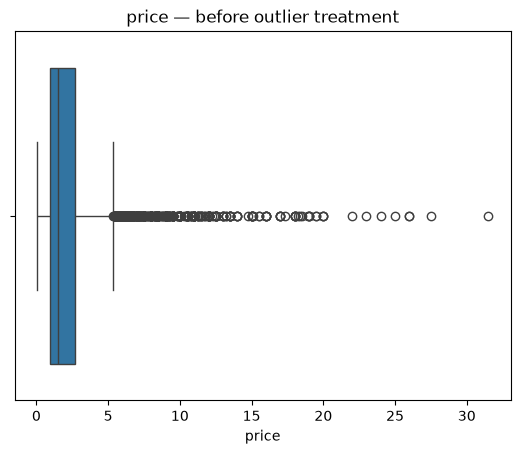

In [10]:
sns.boxplot(x=df['price'])
plt.title('price — before outlier treatment')
plt.show()

In [11]:
Q1, Q3 = df['price_per_sqft'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

sqft_outlier_mask = (df['price_per_sqft'] < lower_bound) | (df['price_per_sqft'] > upper_bound)
outliers_sqft = df[sqft_outlier_mask].copy()
outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x: x * 9 if x < 1000 else x)
outliers_sqft['price_per_sqft'] = round((outliers_sqft['price'] * 10000000) / outliers_sqft['area'])
df.update(outliers_sqft)

df = df[df['price_per_sqft'] <= 50000]
df = df[df['area'] < 100000]

# extreme area values: drop rather than hand-fix by row index (see note above)
df = df[df['area'] <= 10000]

df = df[df['bedRoom'] <= 10]

# same for a stray corrupted carpet_area value — treat as missing instead of guessing
df.loc[df['carpet_area'] > 10000, 'carpet_area'] = np.nan

df['price_per_sqft'] = round((df['price'] * 10000000) / df['area'])

df['area_room_ratio'] = df['area'] / df['bedRoom']
df = df[df['area_room_ratio'] >= 183]

df.to_csv('gurgaon_properties_outlier_treated.csv', index=False)
df.shape

C:\Users\Manish Gholam\AppData\Local\Temp\ipykernel_17976\4246427344.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 1 1 ... 1 0 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.update(outliers_sqft)


(3618, 24)

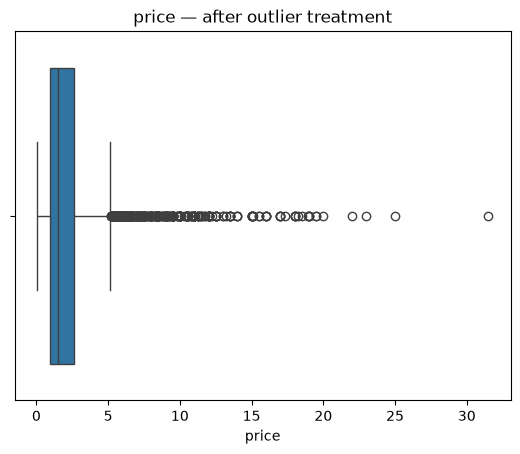

In [12]:
sns.boxplot(x=df['price'])
plt.title('price — after outlier treatment')
plt.show()

## 7. Missing-value imputation
Fills `built_up_area` using the median super/carpet-to-built-up ratio (cascading through the three possible combinations of which fields are present), fills `floorNum` with the median, and imputes `agePossession` via a cascading mode-based rule (by sector+type, then sector, then type). Mirrors `missing-value-imputation.ipynb`.

**Deviation:** the original dropped a single leftover row with a hardcoded `df.drop(index=[2536])`; we drop by condition (any remaining null) instead, which is robust to row order.

**Note:** `floorNum` was extracted with a regex into a string column and never explicitly cast to numeric. In the original project this went unnoticed because every notebook boundary was a `to_csv`/`read_csv` round trip, and `read_csv` auto-infers numeric dtypes — so the next notebook always received it as a proper number. Since this notebook keeps everything in memory, we cast it explicitly instead.

In [13]:
all_present = df[~(df['super_built_up_area'].isnull() | df['built_up_area'].isnull() | df['carpet_area'].isnull())]
super_to_built_up_ratio = (all_present['super_built_up_area'] / all_present['built_up_area']).median()
carpet_to_built_up_ratio = (all_present['carpet_area'] / all_present['built_up_area']).median()

# super + carpet present, built_up missing
mask = ~df['super_built_up_area'].isnull() & df['built_up_area'].isnull() & ~df['carpet_area'].isnull()
df.loc[mask, 'built_up_area'] = round(
    (df.loc[mask, 'super_built_up_area'] / 1.105 + df.loc[mask, 'carpet_area'] / 0.9) / 2
)

# only super present, built_up missing
mask = ~df['super_built_up_area'].isnull() & df['built_up_area'].isnull() & df['carpet_area'].isnull()
df.loc[mask, 'built_up_area'] = round(df.loc[mask, 'super_built_up_area'] / 1.105)

# only carpet present, built_up missing
mask = df['super_built_up_area'].isnull() & df['built_up_area'].isnull() & ~df['carpet_area'].isnull()
df.loc[mask, 'built_up_area'] = round(df.loc[mask, 'carpet_area'] / 0.9)

# a handful of rows have an implausibly small built_up_area for their price — trust 'area' there instead
anomaly_mask = (df['built_up_area'] < 2000) & (df['price'] > 2.5)
df.loc[anomaly_mask, 'built_up_area'] = df.loc[anomaly_mask, 'area']

df = df.drop(columns=['area', 'areaWithType', 'super_built_up_area', 'carpet_area', 'area_room_ratio'])

In [14]:
df['floorNum'] = pd.to_numeric(df['floorNum'])
df.loc[df['floorNum'].isnull(), 'floorNum'] = 2.0  # median floor for houses
df = df.drop(columns=['facing'])
df = df.dropna()  # drops the handful of rows no rule above could resolve


def mode_based_imputation(row, group_cols):
    if row['agePossession'] != 'Undefined':
        return row['agePossession']
    mask = np.logical_and.reduce([df[c] == row[c] for c in group_cols])
    mode_value = df[mask]['agePossession'].mode()
    return mode_value.iloc[0] if not mode_value.empty else np.nan


df['agePossession'] = df.apply(lambda r: mode_based_imputation(r, ['sector', 'property_type']), axis=1)
df['agePossession'] = df.apply(lambda r: mode_based_imputation(r, ['sector']), axis=1)
df['agePossession'] = df.apply(lambda r: mode_based_imputation(r, ['property_type']), axis=1)

df.to_csv('gurgaon_properties_missing_value_imputation.csv', index=False)
df.isnull().sum().sum(), df.shape

(np.int64(0), (3618, 18))

## 8. Feature selection
Derives `luxury_category` and `floor_category` from the numeric `luxury_score` / `floorNum`, then drops columns that earlier feature-importance analysis (in the original `feature-selection.ipynb`, not reproduced here in full since it's exploratory rather than transformational) found uninformative. This is the exact column set `model-selection.ipynb` expects.

In [15]:
def categorize_luxury(score):
    if 0 <= score < 50:
        return 'Low'
    if 50 <= score < 150:
        return 'Medium'
    if 150 <= score <= 175:
        return 'High'
    return None


def categorize_floor(floor):
    if 0 <= floor <= 2:
        return 'Low Floor'
    if 3 <= floor <= 10:
        return 'Mid Floor'
    if 11 <= floor <= 51:
        return 'High Floor'
    return None


df = df.drop(columns=['society', 'price_per_sqft'])
df['luxury_category'] = df['luxury_score'].apply(categorize_luxury)
df['floor_category'] = df['floorNum'].apply(categorize_floor)
df = df.drop(columns=['floorNum', 'luxury_score'])
df = df.drop(columns=['pooja room', 'study room', 'others'])

df.to_csv('gurgaon_properties_post_feature_selection_v2.csv', index=False)
df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,agePossession,built_up_area,servant room,store room,furnishing_type,luxury_category,floor_category
0,flat,sector 65,2.50,3,3,3,Under Construction,1654.0,0,0,0,Low,High Floor
1,flat,sector 48,2.65,4,4,3+,Moderately Old,2134.0,1,0,1,High,High Floor
2,flat,sector 85,1.20,2,2,3,Relatively New,1300.0,0,0,1,High,Mid Floor
3,flat,sector 107,0.52,3,2,2,Relatively New,717.0,0,0,0,Low,Mid Floor
4,flat,sohna road,0.54,2,1,3,New Property,828.0,0,0,0,Medium,Low Floor


## 9. Model comparison
Compares several regressors with 10-fold cross-validation on a `log1p`-transformed target, using the same encoding scheme `model-selection.ipynb` settles on (`OrdinalEncoder` for the low-cardinality categoricals, one-hot for `sector`/`agePossession`).

**Note:** a few sectors have very few listings, so a 10-fold split can leave one entirely out of a training fold. The original notebook's encoders default to erroring on an unseen category (`OrdinalEncoder`/`OneHotEncoder` both error by default); we set `handle_unknown` explicitly so cross-validation doesn't crash on the particular fold split that happens to isolate a rare sector.

In [16]:
df['furnishing_type'] = df['furnishing_type'].replace(
    {0.0: 'unfurnished', 1.0: 'semifurnished', 2.0: 'furnished'}
)

X = df.drop(columns=['price'])
y = df['price']
y_transformed = np.log1p(y)

columns_to_ordinal_encode = [
    'property_type', 'sector', 'balcony', 'agePossession',
    'furnishing_type', 'luxury_category', 'floor_category',
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom', 'bathroom', 'built_up_area', 'servant room', 'store room']),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), columns_to_ordinal_encode),
        ('cat1', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['sector', 'agePossession']),
    ],
    remainder='passthrough',
)

In [17]:
def evaluate(name, model):
    pipe = Pipeline([('preprocessor', preprocessor), ('regressor', model)])
    kfold = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
    r2_scores = cross_val_score(pipe, X, y_transformed, cv=kfold, scoring='r2')

    X_train, X_test, y_train, y_test = train_test_split(
        X, y_transformed, test_size=0.2, random_state=RANDOM_STATE
    )
    pipe.fit(X_train, y_train)
    y_pred = np.expm1(pipe.predict(X_test))
    mae = mean_absolute_error(np.expm1(y_test), y_pred)

    return [name, r2_scores.mean(), mae]


models = {
    'linear_reg': LinearRegression(),
    'svr': SVR(),
    'ridge': Ridge(),
    'lasso': Lasso(),
    'decision_tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'random_forest': RandomForestRegressor(random_state=RANDOM_STATE),
    'extra_trees': ExtraTreesRegressor(random_state=RANDOM_STATE),
    'gradient_boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'adaboost': AdaBoostRegressor(random_state=RANDOM_STATE),
    'mlp': MLPRegressor(random_state=RANDOM_STATE, max_iter=1000),
}

results = pd.DataFrame(
    [evaluate(name, model) for name, model in models.items()],
    columns=['model', 'r2', 'mae'],
).sort_values('mae')
results

C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


...

C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Manish Gholam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,model,r2,mae
6,extra_trees,0.903638,0.503237
5,random_forest,0.898538,0.522617
9,mlp,0.877105,0.577731
7,gradient_boosting,0.877849,0.582383
4,decision_tree,0.819303,0.602483
0,linear_reg,0.857789,0.634158
2,ridge,0.858267,0.634432
8,adaboost,0.756276,0.848286
1,svr,0.766234,0.855177
3,lasso,0.061476,1.545512


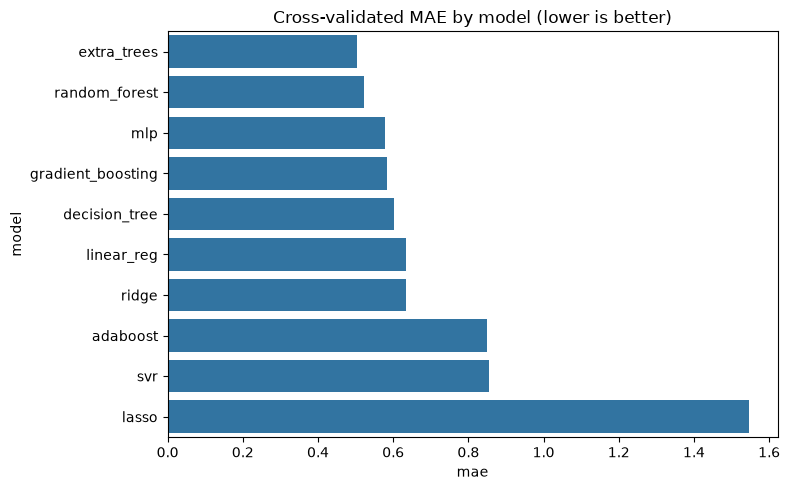

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x='mae', y='model')
plt.title('Cross-validated MAE by model (lower is better)')
plt.tight_layout()
plt.show()

## 10. Train & export the final model
`RandomForestRegressor(n_estimators=500)` is the model `model-selection.ipynb` ultimately exports (its `GridSearchCV` best params — `max_depth=20, max_features='sqrt', max_samples=1.0` — were found on a 128-candidate x 10-fold search that took a long time to run and used `max_features='auto'`, since removed in scikit-learn ≥1.3; we skip re-running that search here and go straight to the config the notebook exports with). `df.pkl` stores the feature frame `app.py` uses to populate its dropdown options.

In [19]:
final_pipeline = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE)),
    ]
)
final_pipeline.fit(X, y_transformed)

with open('pipeline.pkl', 'wb') as f:
    pickle.dump(final_pipeline, f)
with open('df.pkl', 'wb') as f:
    pickle.dump(X, f)

print('Saved pipeline.pkl and df.pkl')
print('Training rows:', X.shape[0])

Saved pipeline.pkl and df.pkl
Training rows: 3618


In [20]:
# sanity check
sample = X.iloc[[0]]
pred = np.expm1(final_pipeline.predict(sample))[0]
print(f'Predicted: {pred:.2f} Cr  |  Actual: {y.iloc[0]:.2f} Cr')

Predicted: 2.58 Cr  |  Actual: 2.50 Cr
